# Proyecto Final (Hito 4) — Minería de Datos (Data Hunters)
## Segmentación y Detección Georreferenciada de Descalce en Obras Públicas del Sistema Invierte.pe

**Integrantes:**
- Fernando Torres Valdivia
- Romy Tipacti Carrasco
- Arturo Álvarez de la Torre

**Docente:** Soledad Espezúa Llerena  
**Curso:** Data Mining — Universidad del Pacífico  
**Repositorio GitHub:** `https://github.com/RomyUP1411/data-mining-project`

---

# <font color=blue>I. Introducción</font>

- **Contexto y problema:** El Sistema Nacional de Programación Multianual y Gestión de Inversiones (**Invierte.pe**) conduce la asignación de recursos públicos para infraestructura en el Perú. Pese a la magnitud del presupuesto anual, la supervisión operativa enfrenta una desconexión crítica: el módulo presupuestal (`Seguimiento_PI` del MEF) registra los desembolsos financieros devengados, mientras que el sistema de contrataciones (`Proceso_Seleccion` del SEACE e Infobras) registra por separado los contratos y el porcentaje de avance físico en campo. Esta falta de conciliación periódica origina el problema del **descalce financiero-físico**: obras que devengan gran parte de su presupuesto sin registrar un avance físico equivalente, o que acumulan cientos de contratos y adendas durante más de una década, desembocando en sobrecostos y obras paralizadas.
- **Usuario y beneficiarios del proyecto:** Los resultados de este trabajo benefician directamente a tres usuarios:
  1. **Contraloría General de la República (CGR) y Órganos de Control Institucional (OCI):** pasan de revisar manualmente miles de expedientes a contar con un filtro objetivo de triaje sobre las obras atípicas de mayor riesgo.
  2. **Dirección General de Programación Multianual de Inversiones (DGPMI - MEF):** obtiene tipologías empíricas para diferenciar el seguimiento presupuestal entre ministerios, gobiernos regionales y municipalidades.
  3. **Unidades Ejecutoras subnacionales y ciudadanía:** permite detectar cuellos de botella contractuales en obras de salud, saneamiento, educación y transporte antes de que queden paralizadas.
- **Objetivo del proyecto:** Segmentar de manera no supervisada la cartera activa de proyectos de inversión pública ($N = 2,067$ CUI) para caracterizar tipologías operativas de ejecución, aislar proyectos atípicos (*outliers*) con alto descalce o fragmentación contractual y georreferenciar los resultados en un mapa interactivo HTML que oriente la priorización del control gubernamental.
- **Pregunta de análisis:** *¿Es posible identificar tipologías estructurales de proyectos de inversión pública y localizar territorialmente perfiles atípicos de descalce financiero-físico mediante técnicas de clustering no supervisado aplicadas sobre datos transaccionales del MEF?*
- **Aporte del trabajo:** Frente a la supervisión tradicional basada únicamente en el monto de la obra, este trabajo aporta: (i) una matriz analítica reproducible a nivel de proyecto CUI que cuantifica la brecha gasto-avance y la carga contractual; (ii) una representación bidimensional con **NMF** que evita el aplastamiento visual provocado por megaproyectos extremos en PCA; (iii) la triangulación de **K-Means ($K=3$)**, **Jerárquico Ward ($K=3$)** y **DBSCAN ($arepsilon=1.8$)**, logrando capturar en el $8.42\%$ de ruido de DBSCAN una tasa de alerta crítica ($37.93\%$) que más que triplica al resto de la cartera ($11.41\%$); (iv) un mapa interactivo multicapa en **Folium (`mapa_clusters.html`)** para la inspección territorial por región; y (v) una regla operativa (`scaler.transform`, percentil 95 de distancia al centroide y vecindad a puntos núcleo) para evaluar nuevos proyectos sin reentrenar los modelos.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import folium

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import NMF
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8.5, 4.5)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

# <font color=blue>II. Datos y Representación Final</font>

## <font color=green>1. Fuentes, unidad de análisis y atributos seleccionados</font>

La matriz analítica final (`matriz_analitica_final.csv`) integra los registros transaccionales de **`Seguimiento_PI`** (ejecución presupuestal del MEF) y **`Proceso_Seleccion`** (contratos y avance físico reportado), junto con los shapefiles oficiales del **Instituto Geográfico Nacional (IGN)** (`peru_shapes`).

- **Unidad de análisis:** **Una fila = un proyecto de inversión pública único (CUI)** en ejecución activa ($N = 2,067$ proyectos).
- **Atributos que entran al cálculo de distancias (12 variables):**
  1. **Descalce y ejecución:** `pct_ejecucion_financiera`, `avance_fisico_pct`, `brecha_gasto_avance` ($\text{\% gasto} - \text{\% avance físico}$).
  2. **Magnitud presupuestal:** `costo_inversion`, `gasto_total`, `gasto_anual_promedio`.
  3. **Maduración y contratación:** `tiempo_maduracion_anios`, `n_registros_presupuesto`, `n_contratos`, `tamano_inversion_ord`.
  4. **Nivel de gobierno (One-Hot):** `gob_GOBIERNOS LOCALES`, `gob_GOBIERNOS REGIONALES` (Gobierno Nacional como categoría base).
- **Exclusiones y escalamiento:** Excluimos identificadores (`codigo_proyecto`, `nombre_proyecto`), región (`departamento`, reservada para la georreferenciación) y la variable de alerta **`flag_gasto_adelantado`** (1 si `brecha_gasto_avance > 15%`, 0 si no), la cual **no participa** en las distancias y se usa al final para describir el riesgo de cada grupo. Estandarizamos los 12 atributos con **`StandardScaler`** (`X_std`).

In [2]:
ruta_datos = (
    "matriz_analitica_final.csv"
    if os.path.exists("matriz_analitica_final.csv")
    else ("Entrega_4/matriz_analitica_final.csv" if os.path.exists("Entrega_4/matriz_analitica_final.csv") else ("Entrega_3/matriz_analitica_final.csv" if os.path.exists("Entrega_3/matriz_analitica_final.csv") else "Entrega_4/matriz_analitica_con_clusters.csv"))
)
df = pd.read_csv(ruta_datos)

features = [
    "pct_ejecucion_financiera",
    "avance_fisico_pct",
    "brecha_gasto_avance",
    "costo_inversion",
    "gasto_total",
    "tiempo_maduracion_anios",
    "gasto_anual_promedio",
    "n_registros_presupuesto",
    "n_contratos",
    "tamano_inversion_ord",
    "gob_GOBIERNOS LOCALES",
    "gob_GOBIERNOS REGIONALES"
]

X = df[features].copy()

# Ajustamos StandardScaler para los algoritmos basados en distancia
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

df_resultados = df.copy()

print("Dimensiones de X_std:", X_std.shape)
display(df[["codigo_proyecto", "nombre_proyecto", "nivel_gobierno", "departamento", "costo_inversion", "avance_fisico_pct", "brecha_gasto_avance", "n_contratos"]].head(3))

Dimensiones de X_std: (2067, 12)


,codigo_proyecto,nombre_proyecto,nivel_gobierno,departamento,costo_inversion,avance_fisico_pct,brecha_gasto_avance,n_contratos
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,GOBIERNO NACIONAL,LIMA,263517133.53,100.00,-29.71,63.00
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,GOBIERNO NACIONAL,LIMA,269114681.55,100.00,-35.35,27.00
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,GOBIERNOS REGIONALES,ANCASH,189747493.86,100.00,-63.39,38.00


# <font color=blue>III. Metodología y Reducción Dimensional con NMF</font>

## <font color=green>2. Técnicas seleccionadas y representación en 2D con NMF (`NMF1` y `NMF2`)</font>

Nuestro flujo de análisis articula tres técnicas de clustering sobre la matriz estandarizada (`X_std`): **K-Means** (particional), **Clustering Jerárquico de Ward** (aglomerativo por mínima varianza) y **DBSCAN** (basado en densidad para aislar proyectos atípicos como ruido), cuyos resultados se georreferencian posteriormente en **Folium** (`mapa_clusters.html`).

Para proyectar los 12 atributos en dos dimensiones y visualizar los segmentos sin que el valor extremo de la Línea 2 del Metro aplaste la escala gráfica (como ocurre en PCA), aplicamos **`MinMaxScaler`** ($X_{\text{pos}} \in [0, 1]$) seguido de **NMF** ($X_{\text{pos}} \approx W H$, con $W, H \ge 0$):
- La matriz $H$ indica el peso de cada atributo original en los factores.
- La matriz $W$ (`NMF1`, `NMF2`) proporciona las coordenadas 2D de cada proyecto para graficar los datos y los clusters.

Dimensión de W: (2067, 2) | Dimensión de H: (2, 12) | Error de reconstrucción NMF: 22.659


,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos,tamano_inversion_ord,gob_GOBIERNOS LOCALES,gob_GOBIERNOS REGIONALES
NMF1,0.11,1.34,0.16,0.01,0.02,0.99,0.02,0.36,0.09,1.18,0.00,1.25
NMF2,0.07,0.75,0.09,0.00,0.00,0.37,0.00,0.10,0.03,0.26,0.89,0.00


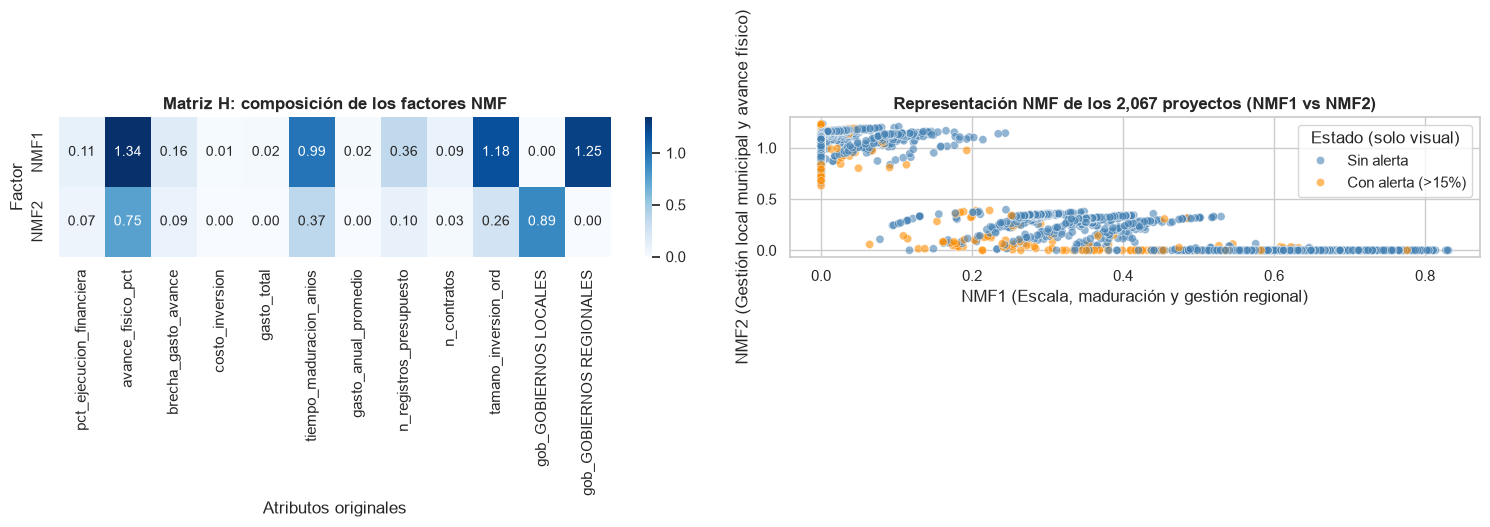

In [3]:
scaler_mm = MinMaxScaler()
X_pos = scaler_mm.fit_transform(X)

nmf = NMF(
    n_components=2,
    init="random",
    random_state=1,
    max_iter=2000
)

W = nmf.fit_transform(X_pos)
H = nmf.components_

df_resultados["NMF1"] = W[:, 0]
df_resultados["NMF2"] = W[:, 1]

print("Dimensión de W:", W.shape, "| Dimensión de H:", H.shape, "| Error de reconstrucción NMF:", round(nmf.reconstruction_err_, 3))

H_df = pd.DataFrame(H, index=["NMF1", "NMF2"], columns=features)
display(H_df.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))

sns.heatmap(H_df, annot=True, fmt=".2f", cmap="Blues", ax=ax1)
ax1.set_title("Matriz H: composición de los factores NMF", fontweight="bold")
ax1.set_xlabel("Atributos originales")
ax1.set_ylabel("Factor")

alerta_str = df_resultados["flag_gasto_adelantado"].map({0: "Sin alerta", 1: "Con alerta (>15%)"})
sns.scatterplot(
    x=df_resultados["NMF1"],
    y=df_resultados["NMF2"],
    hue=alerta_str,
    palette={"Sin alerta": "steelblue", "Con alerta (>15%)": "darkorange"},
    alpha=0.6,
    s=35,
    ax=ax2
)
ax2.set_title("Representación NMF de los 2,067 proyectos (NMF1 vs NMF2)", fontweight="bold")
ax2.set_xlabel("NMF1 (Escala, maduración y gestión regional)")
ax2.set_ylabel("NMF2 (Gestión local municipal y avance físico)")
ax2.legend(title="Estado (solo visual)")

plt.tight_layout()
plt.show()

# <font color=blue>IV. Diseño Experimental</font>

## <font color=green>3. Evaluación de K-Means con $K$ creciente ($K = 2, \dots, 8$)</font>

Comparamos $K \in [2, 8]$ utilizando tres métricas internas y dos indicadores de negocio:
- **Inercia:** baja al crecer $K$; buscamos el **codo** donde se estabiliza la caída.
- **Silhouette:** entre $-1$ y $1$; **más alto es mejor**.
- **Davies-Bouldin:** $\ge 0$; **más bajo es mejor**.
- **`segmento_mas_pequeno` y `dif_alerta`:** tamaño del grupo más pequeño y rango de tasas de alerta entre segmentos.

Evaluación de K-Means para K = 2, ..., 8 (Inercia en K=1: 24804.00):


,K,inercia,reduccion_inercia_%,silhouette,davies_bouldin,segmento_mas_pequeno,dif_alerta
0,2,20711.38,16.50,0.23,1.78,891,0.01
1,3,16628.09,19.72,0.23,1.19,1,0.14
2,4,14893.49,10.43,0.20,1.44,1,0.15
3,5,13484.85,9.46,0.21,1.34,1,1.00
4,6,12034.53,10.76,0.21,1.24,1,1.00
5,7,11005.94,8.55,0.22,1.23,1,1.00
6,8,9979.17,9.33,0.22,1.13,1,1.00


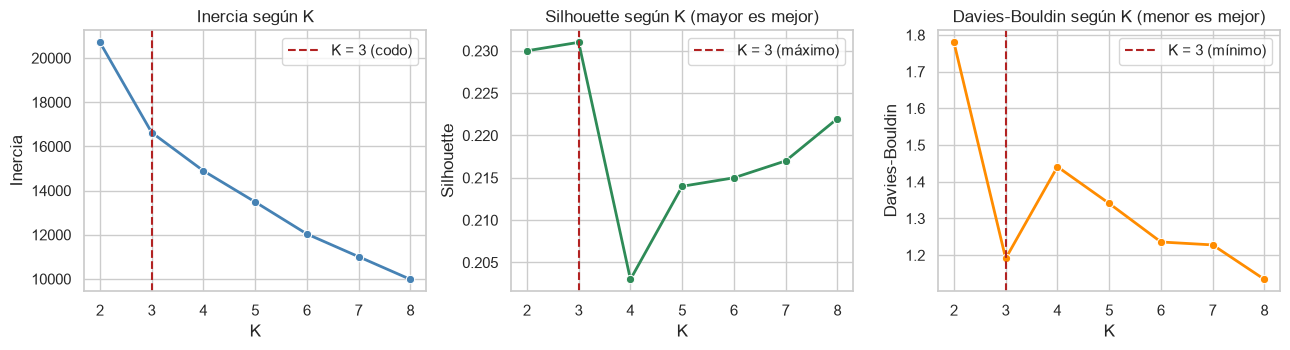

In [4]:
inercia_k1 = KMeans(n_clusters=1, init="k-means++", n_init=10, random_state=42).fit(X_std).inertia_

resultados_kmeans = []
inercia_prev = inercia_k1

for k in range(2, 9):
    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    labels = modelo.fit_predict(X_std)

    alerta = df_resultados.groupby(labels)["flag_gasto_adelantado"].mean()
    tamanos = pd.Series(labels).value_counts()
    reduccion = inercia_prev - modelo.inertia_
    reduccion_pct = (reduccion / inercia_prev) * 100
    inercia_prev = modelo.inertia_

    resultados_kmeans.append({
        "K": k,
        "inercia": round(modelo.inertia_, 2),
        "reduccion_inercia_%": round(reduccion_pct, 2),
        "silhouette": round(silhouette_score(X_std, labels), 3),
        "davies_bouldin": round(davies_bouldin_score(X_std, labels), 3),
        "segmento_mas_pequeno": int(tamanos.min()),
        "dif_alerta": round(alerta.max() - alerta.min(), 3)
    })

metricas_kmeans = pd.DataFrame(resultados_kmeans)
print("Evaluación de K-Means para K = 2, ..., 8 (Inercia en K=1: {:.2f}):".format(inercia_k1))
display(metricas_kmeans)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

sns.lineplot(data=metricas_kmeans, x="K", y="inercia", marker="o", color="steelblue", linewidth=2, ax=axes[0])
axes[0].axvline(3, color="firebrick", linestyle="--", label="K = 3 (codo)")
axes[0].set(title="Inercia según K", xlabel="K", ylabel="Inercia")
axes[0].legend()

sns.lineplot(data=metricas_kmeans, x="K", y="silhouette", marker="o", color="seagreen", linewidth=2, ax=axes[1])
axes[1].axvline(3, color="firebrick", linestyle="--", label="K = 3 (máximo)")
axes[1].set(title="Silhouette según K (mayor es mejor)", xlabel="K", ylabel="Silhouette")
axes[1].legend()

sns.lineplot(data=metricas_kmeans, x="K", y="davies_bouldin", marker="o", color="darkorange", linewidth=2, ax=axes[2])
axes[2].axvline(3, color="firebrick", linestyle="--", label="K = 3 (mínimo)")
axes[2].set(title="Davies-Bouldin según K (menor es mejor)", xlabel="K", ylabel="Davies-Bouldin")
axes[2].legend()

plt.tight_layout(), dpi=300, bbox_inches="tight")
plt.show()

## <font color=green>4. Calibración de DBSCAN (`k-distancias`) y comparación de enlaces en Clustering Jerárquico ($K = 3$)</font>

- **En K-Means:** las tres métricas coinciden en **`K_ELEGIDO = 3`** (codo de inercia con caída de $-19.72\%$, **máximo global de Silhouette en $0.231$** y **mínimo de Davies-Bouldin en $1.191$**, mientras que en $K=4$ el Silhouette cae a su mínimo de $0.203$).
- **En DBSCAN:** con `min_samples = 24` ($2 \times 12$ variables), evaluamos `eps` creciente e identificamos el codo en **`eps = 1.8`**, donde se estabilizan **3 grupos densos** y se separa un **$8.42\%$ de ruido ($174$ proyectos atípicos)**.
- **En Jerárquico:** comparamos `single`, `complete`, `average` y `ward` en $K = 3$, verificando en el dendrograma de Ward el corte en distancia $= 8.5$.

Sensibilidad de DBSCAN según eps (min_samples = 24):


,eps,n_clusters,n_ruido,ruido_%
0,1.20,3,679,32.85
1,1.50,3,291,14.08
2,1.80,3,174,8.42
3,2.00,3,131,6.34
4,2.20,2,112,5.42
5,2.50,1,88,4.26


Comparación de criterios de enlace jerárquico para K = 3:


,linkage,n_clusters,segmento_mas_pequeno,segmento_mas_grande,silhouette
0,single,3,1,2063,0.80
1,complete,3,1,2063,0.80
2,average,3,1,2063,0.80
3,ward,3,1,1522,0.25


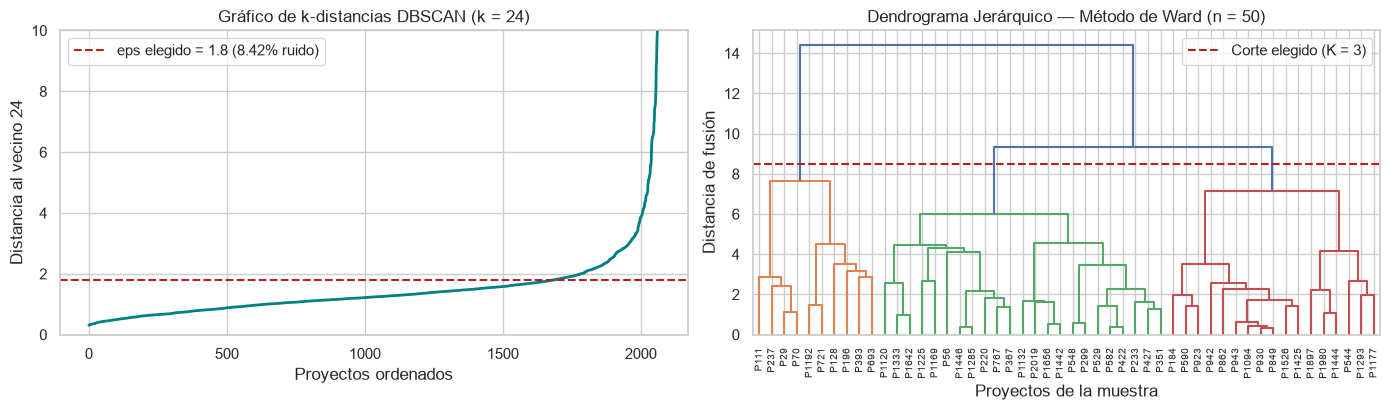

In [5]:
min_samples = 24
vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X_std)
distancias, _ = vecinos.kneighbors(X_std)
k_dist = np.sort(distancias[:, min_samples - 1])

comparacion_eps = []
for eps in [1.2, 1.5, 1.8, 2.0, 2.2, 2.5]:
    labels_db = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_std)
    etiquetas = set(labels_db)
    n_clusters = len(etiquetas) - (1 if -1 in etiquetas else 0)
    n_ruido = int(np.sum(labels_db == -1))
    comparacion_eps.append({
        "eps": eps,
        "n_clusters": n_clusters,
        "n_ruido": n_ruido,
        "ruido_%": round((n_ruido / len(X_std)) * 100, 2)
    })

print("Sensibilidad de DBSCAN según eps (min_samples = 24):")
display(pd.DataFrame(comparacion_eps))

# Comparación de enlaces jerárquicos para K = 3
resumen_linkage = []
for metodo in ["single", "complete", "average", "ward"]:
    labels_h = AgglomerativeClustering(n_clusters=3, linkage=metodo).fit_predict(X_std)
    conteos = pd.Series(labels_h).value_counts()
    resumen_linkage.append({
        "linkage": metodo,
        "n_clusters": len(conteos),
        "segmento_mas_pequeno": conteos.min(),
        "segmento_mas_grande": conteos.max(),
        "silhouette": round(silhouette_score(X_std, labels_h), 3)
    })

print("Comparación de criterios de enlace jerárquico para K = 3:")
display(pd.DataFrame(resumen_linkage))

np.random.seed(42)
indices_muestra = np.random.choice(len(df), size=50, replace=False)
Z_ward_muestra = linkage(X_std[indices_muestra], method="ward")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))

ax1.plot(k_dist, color="teal", linewidth=2)
ax1.axhline(y=1.8, color="firebrick", linestyle="--", label="eps elegido = 1.8 (8.42% ruido)")
ax1.set_ylim(0, 10)
ax1.set(title=f"Gráfico de k-distancias DBSCAN (k = {min_samples})", xlabel="Proyectos ordenados", ylabel=f"Distancia al vecino {min_samples}")
ax1.legend()

plt.sca(ax2)
dendrogram(Z_ward_muestra, labels=[f"P{i}" for i in indices_muestra], leaf_rotation=90, leaf_font_size=7, color_threshold=8.5)
ax2.axhline(y=8.5, color="firebrick", linestyle="--", label="Corte elegido (K = 3)")
ax2.set(title="Dendrograma Jerárquico — Método de Ward (n = 50)", xlabel="Proyectos de la muestra", ylabel="Distancia de fusión")
ax2.legend()

plt.tight_layout(), dpi=300, bbox_inches="tight")
plt.show()

# <font color=blue>V. Resultados</font>

## <font color=green>5. Configuración final de K-Means ($K = 3$), Silhouette por proyecto y perfil de segmentos</font>

Ajustamos K-Means con `K_ELEGIDO = 3`, revisamos la distribución de $s(i)$ por proyecto (`silhouette_samples`) y calculamos el perfil promedio en unidades originales junto con el mapa de calor en valores Z.

Resumen de Silhouette por segmento en K-Means (K = 3):


,n,silueta_media,n_negativos
cluster_kmeans,,,
0,892,0.09,254
1,1174,0.34,0
2,1,0.00,0


Perfil promedio por segmento en unidades originales (K = 3):


,n,porcentaje_%,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos,tasa_alerta_%
cluster_kmeans,,,,,,,,,,,,
0,892,43.15,42.39,70.33,-27.95,74055808.97,24345171.81,12.69,1878350.87,18.52,229.69,13.12
1,1174,56.80,61.52,80.53,-19.01,5537501.57,2636421.72,9.57,284611.02,10.29,120.96,14.05
2,1,0.05,15.22,50.42,-35.20,12075451952.74,1837811051.69,13.00,141370080.90,34.00,72.00,0.00


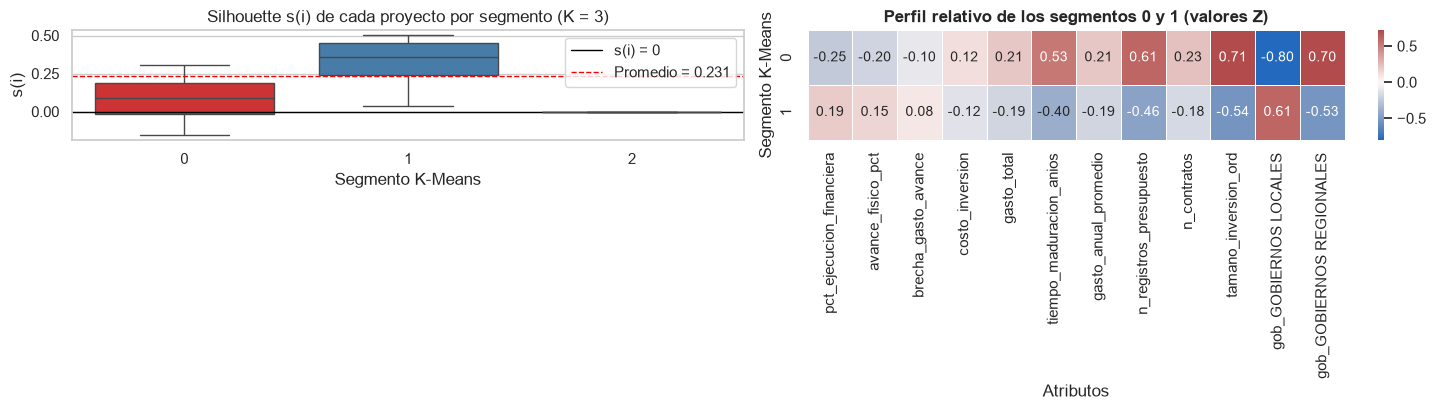

In [6]:
K_ELEGIDO = 3
kmeans_final = KMeans(n_clusters=K_ELEGIDO, init="k-means++", n_init=10, random_state=42)
df_resultados["cluster_kmeans"] = kmeans_final.fit_predict(X_std)
df_resultados["silhouette_km"] = silhouette_samples(X_std, df_resultados["cluster_kmeans"])

promedio_sil = df_resultados["silhouette_km"].mean()
resumen_sil_seg = (
    df_resultados.groupby("cluster_kmeans")["silhouette_km"]
    .agg(n="count", silueta_media="mean", n_negativos=lambda s: (s < 0).sum())
    .round(3)
)
print("Resumen de Silhouette por segmento en K-Means (K = 3):")
display(resumen_sil_seg)

atributos_perfil = [
    "pct_ejecucion_financiera",
    "avance_fisico_pct",
    "brecha_gasto_avance",
    "costo_inversion",
    "gasto_total",
    "tiempo_maduracion_anios",
    "gasto_anual_promedio",
    "n_registros_presupuesto",
    "n_contratos"
]

perfil_km = df_resultados.groupby("cluster_kmeans")[atributos_perfil].mean().round(2)
perfil_km.insert(0, "n", df_resultados.groupby("cluster_kmeans").size())
perfil_km.insert(1, "porcentaje_%", (df_resultados["cluster_kmeans"].value_counts(normalize=True).sort_index() * 100).round(2))
perfil_km["tasa_alerta_%"] = (df_resultados.groupby("cluster_kmeans")["flag_gasto_adelantado"].mean() * 100).round(2)

print("Perfil promedio por segmento en unidades originales (K = 3):")
display(perfil_km)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.2))

sns.boxplot(data=df_resultados, x="cluster_kmeans", y="silhouette_km", palette="Set1", ax=ax1)
ax1.axhline(0, color="black", linewidth=1, label="s(i) = 0")
ax1.axhline(promedio_sil, color="red", linestyle="--", linewidth=1, label=f"Promedio = {promedio_sil:.3f}")
ax1.set(title="Silhouette s(i) de cada proyecto por segmento (K = 3)", xlabel="Segmento K-Means", ylabel="s(i)")
ax1.legend()

perfil_z = (df_resultados.groupby("cluster_kmeans")[features].mean().loc[[0, 1]] - X.mean()) / X.std()
sns.heatmap(perfil_z, annot=True, fmt=".2f", center=0, cmap="vlag", linewidths=0.5, ax=ax2)
ax2.set_title("Perfil relativo de los segmentos 0 y 1 (valores Z)", fontweight="bold")
ax2.set_xlabel("Atributos")
ax2.set_ylabel("Segmento K-Means")

plt.tight_layout()
plt.show()

## <font color=green>6. Comparación con Jerárquico Ward ($K = 3$) y DBSCAN (`eps = 1.8`) en el plano NMF</font>

Ajustamos las configuraciones finales de Jerárquico Ward ($K = 3$) y DBSCAN ($\varepsilon = 1.8, \text{min\_samples} = 24$), caracterizamos los **174 outliers (`ruido = -1`)** y comparamos las tres particiones en el plano de factores no negativos (`NMF1` vs `NMF2`).

Perfil promedio: Outliers de DBSCAN (ruido = -1) vs. Proyectos en clusters densos:


,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos,tasa_alerta_%
"Proyectos en clusters densos (n=1,893)",50.26,76.87,-26.61,20919039.63,6762532.18,10.80,606422.90,13.09,135.18,11.41
Outliers / Ruido DBSCAN (n=174),85.73,67.91,17.82,258819071.05,79582701.13,12.25,5764562.27,22.22,523.36,37.93


1. Tabla de contingencia: K-Means (K = 3) vs. Jerárquico Ward (K = 3):


Jerárquico Ward,0,1,2
K-Means,,,
0,386,0,506
1,1136,0,38
2,0,1,0



2. Tabla de contingencia: DBSCAN vs. K-Means (K = 3):


K-Means,0,1,2
DBSCAN,,,
0,269,232,0
1,456,26,0
2,36,874,0
ruido,131,42,1


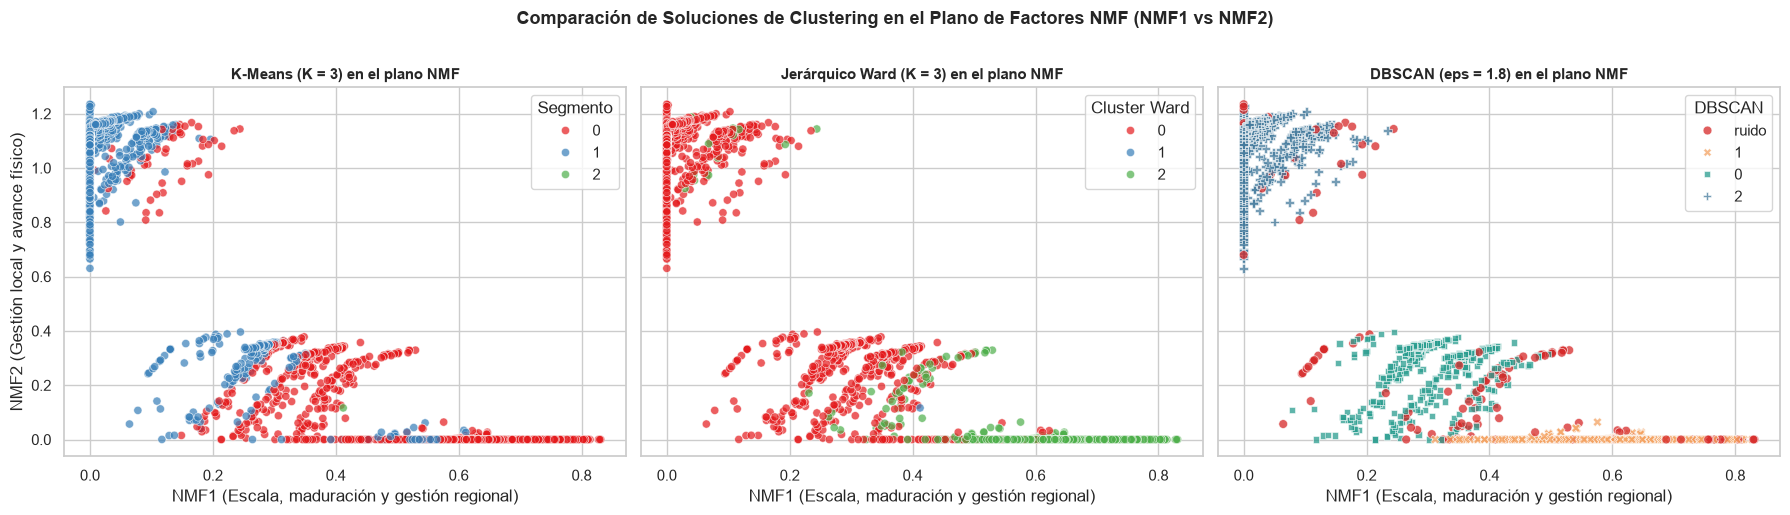

In [7]:
hier_final = AgglomerativeClustering(n_clusters=3, linkage="ward")
df_resultados["cluster_hier"] = hier_final.fit_predict(X_std)

dbscan_final = DBSCAN(eps=1.8, min_samples=min_samples)
df_resultados["cluster_dbscan"] = dbscan_final.fit_predict(X_std)
df_resultados["es_ruido"] = df_resultados["cluster_dbscan"] == -1
df_resultados["grupo_dbscan"] = df_resultados["cluster_dbscan"].astype(str).replace({"-1": "ruido"})

perfil_ruido = df_resultados.groupby("es_ruido")[atributos_perfil].mean().round(2)
perfil_ruido["flag_gasto_adelantado"] = (df_resultados.groupby("es_ruido")["flag_gasto_adelantado"].mean() * 100).round(2)
perfil_ruido.index = ["Proyectos en clusters densos (n=1,893)", "Outliers / Ruido DBSCAN (n=174)"]
perfil_ruido = perfil_ruido.rename(columns={"flag_gasto_adelantado": "tasa_alerta_%"})

print("Perfil promedio: Outliers de DBSCAN (ruido = -1) vs. Proyectos en clusters densos:")
display(perfil_ruido)

print("1. Tabla de contingencia: K-Means (K = 3) vs. Jerárquico Ward (K = 3):")
display(pd.crosstab(df_resultados["cluster_kmeans"], df_resultados["cluster_hier"], rownames=["K-Means"], colnames=["Jerárquico Ward"]))

print("\n2. Tabla de contingencia: DBSCAN vs. K-Means (K = 3):")
display(pd.crosstab(df_resultados["grupo_dbscan"], df_resultados["cluster_kmeans"], rownames=["DBSCAN"], colnames=["K-Means"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

sns.scatterplot(data=df_resultados, x="NMF1", y="NMF2", hue=df_resultados["cluster_kmeans"].astype("category"), palette="Set1", alpha=0.7, s=35, ax=axes[0])
axes[0].set_title("K-Means (K = 3) en el plano NMF", fontsize=11, fontweight="bold")
axes[0].set_xlabel("NMF1 (Escala, maduración y gestión regional)")
axes[0].set_ylabel("NMF2 (Gestión local y avance físico)")
axes[0].legend(title="Segmento", loc="upper right")

sns.scatterplot(data=df_resultados, x="NMF1", y="NMF2", hue=df_resultados["cluster_hier"].astype("category"), palette="Set1", alpha=0.7, s=35, ax=axes[1])
axes[1].set_title("Jerárquico Ward (K = 3) en el plano NMF", fontsize=11, fontweight="bold")
axes[1].set_xlabel("NMF1 (Escala, maduración y gestión regional)")
axes[1].legend(title="Cluster Ward", loc="upper right")

sns.scatterplot(data=df_resultados, x="NMF1", y="NMF2", hue="grupo_dbscan", style="grupo_dbscan",
                palette={"0": "#2a9d8f", "1": "#f4a261", "2": "#457b9d", "ruido": "#d62828"}, alpha=0.75, s=40, ax=axes[2])
axes[2].set_title("DBSCAN (eps = 1.8) en el plano NMF", fontsize=11, fontweight="bold")
axes[2].set_xlabel("NMF1 (Escala, maduración y gestión regional)")
axes[2].legend(title="DBSCAN", loc="upper right")

plt.suptitle("Comparación de Soluciones de Clustering en el Plano de Factores NMF (NMF1 vs NMF2)", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout(), dpi=300, bbox_inches="tight")
plt.show()

## <font color=green>7. Clustering georreferenciado y outliers de DBSCAN en HTML con GeoPandas y Folium (`mapa_clusters.html`)</font>

Unimos los resultados de K-Means ($K = 3$) y los **174 outliers de DBSCAN (`ruido = -1`)** con los shapefiles departamentales del IGN (`peru_shapes`), calculamos las métricas espaciales en proyección métrica UTM Zona 18S (`EPSG:32718`) y generamos el mapa interactivo **`mapa_clusters.html`** en Folium.

Resumen georreferenciado por región (Cluster K-Means predominante y Outliers DBSCAN):


,ADM1_PCODE,ADM1_ES,n_proyectos,perfil_regional,n_outliers,pct_outliers,outliers_10mil_km2,costo_outliers_millones,contratos_prom_outliers
14,PE15,Lima,565,Seg. 0: Regional/Nacional Complejo,74,13.10,21.13,31391.69,317.30
7,PE08,Cusco,289,Seg. 1: Local Municipal Compacto,13,4.50,1.80,2157.21,491.90
24,PE25,Ucayali,29,Seg. 0: Regional/Nacional Complejo,12,41.38,1.14,1200.29,2430.70
4,PE05,Ayacucho,104,Seg. 1: Local Municipal Compacto,7,6.73,1.61,560.43,583.00
19,PE20,Piura,54,Seg. 1: Local Municipal Compacto,7,12.96,1.95,690.31,217.90
8,PE09,Huancavelica,41,Seg. 1: Local Municipal Compacto,6,14.63,2.72,480.54,277.20
0,PE01,Amazonas,62,Seg. 0: Regional/Nacional Complejo,6,9.68,1.52,259.73,345.70
3,PE04,Arequipa,133,Seg. 1: Local Municipal Compacto,6,4.51,0.95,3095.20,321.00
1,PE02,Ancash,98,Seg. 1: Local Municipal Compacto,6,6.12,1.67,78.45,110.00
20,PE21,Puno,113,Seg. 1: Local Municipal Compacto,6,5.31,0.88,416.24,709.70


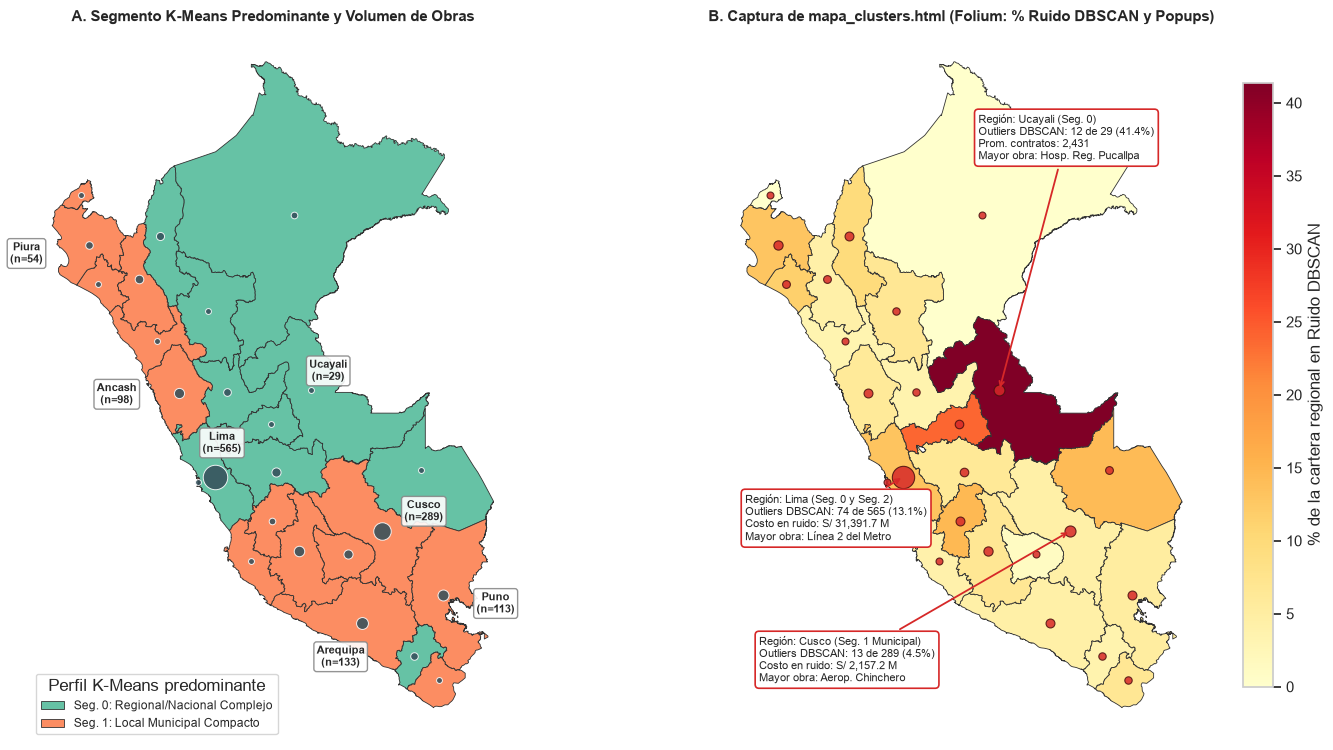

In [8]:
import zipfile
ruta_shapes = (
    "peru_shapes"
    if os.path.exists("peru_shapes")
    else ("Entrega_4/peru_shapes" if os.path.exists("Entrega_4/peru_shapes") else "Entrega_3/peru_shapes")
)
if not os.path.exists(os.path.join(ruta_shapes, "per_admbnda_adm1_ign_20200714.shp")):
    ruta_zip = "peru_shapes.zip" if os.path.exists("peru_shapes.zip") else ("../Entrega_3/peru_shapes.zip" if os.path.exists("../Entrega_3/peru_shapes.zip") else "Entrega_3/peru_shapes.zip")
    os.makedirs(ruta_shapes, exist_ok=True)
    with zipfile.ZipFile(ruta_zip, "r") as zf:
        zf.extractall(ruta_shapes)
regiones = gpd.read_file(os.path.join(ruta_shapes, "per_admbnda_adm1_ign_20200714.shp"))

df_resultados["ADM1_ES"] = (
    df_resultados["departamento"]
    .str.strip()
    .str.title()
    .replace({
        "Provincia Constitucional Del Callao": "Callao",
        "Madre De Dios": "Madre de Dios"
    })
)

df_geo = df_resultados[df_resultados["ADM1_ES"] != ""].copy()
outliers_df = df_geo[df_geo["cluster_dbscan"] == -1].copy()

obra_top_region = (
    outliers_df.sort_values("costo_inversion", ascending=False)
    .groupby("ADM1_ES")
    .first()[["codigo_proyecto", "nombre_proyecto", "costo_inversion", "n_contratos", "brecha_gasto_avance"]]
    .reset_index()
)

resumen_regional = (
    df_geo.groupby("ADM1_ES")
    .agg(
        n_proyectos=("codigo_proyecto", "size"),
        cluster_predom=("cluster_kmeans", lambda s: int(s.mode()[0])),
        pct_seg0=("cluster_kmeans", lambda s: round((s == 0).mean() * 100, 1)),
        pct_seg1=("cluster_kmeans", lambda s: round((s == 1).mean() * 100, 1)),
        n_outliers=("es_ruido", "sum"),
        pct_outliers=("es_ruido", lambda s: round(s.mean() * 100, 2)),
        costo_outliers_millones=("costo_inversion", lambda s: round(s[df_geo.loc[s.index, "es_ruido"]].sum() / 1e6, 2)),
        contratos_prom_outliers=("n_contratos", lambda s: round(s[df_geo.loc[s.index, "es_ruido"]].mean(), 1))
    )
    .reset_index()
    .merge(obra_top_region, on="ADM1_ES", how="left")
)

crs_metros = regiones.estimate_utm_crs()
regiones_m = regiones.to_crs(crs_metros)
regiones_m["area_km2"] = (regiones_m.area / 1_000_000).round(1)

regiones_outliers = regiones_m.merge(resumen_regional, on="ADM1_ES", how="left")
regiones_outliers["n_proyectos"] = regiones_outliers["n_proyectos"].fillna(0).astype(int)
regiones_outliers["n_outliers"] = regiones_outliers["n_outliers"].fillna(0).astype(int)
regiones_outliers["pct_outliers"] = regiones_outliers["pct_outliers"].fillna(0.0)
regiones_outliers["costo_outliers_millones"] = regiones_outliers["costo_outliers_millones"].fillna(0.0)
regiones_outliers["outliers_10mil_km2"] = (
    regiones_outliers["n_outliers"] / regiones_outliers["area_km2"] * 10_000
).round(2)
regiones_outliers["perfil_regional"] = regiones_outliers["cluster_predom"].map({
    0.0: "Seg. 0: Regional/Nacional Complejo",
    1.0: "Seg. 1: Local Municipal Compacto"
}).fillna("Sin datos")

print("Resumen georreferenciado por región (Cluster K-Means predominante y Outliers DBSCAN):")
display(
    regiones_outliers[[
        "ADM1_PCODE", "ADM1_ES", "n_proyectos", "perfil_regional",
        "n_outliers", "pct_outliers", "outliers_10mil_km2", "costo_outliers_millones", "contratos_prom_outliers"
    ]].sort_values("n_outliers", ascending=False).head(12)
)

# Mapas estáticos comparativos con GeoPandas (reproduce Fig. 5 del paper con valores exactos)
reg_plot = regiones_outliers.to_crs("EPSG:4326").copy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7.6))

# Panel A: Perfil K-Means predominante + volumen de obras
reg_plot.plot(
    column="perfil_regional", categorical=True, cmap="Set2", edgecolor="#333333", linewidth=0.6,
    legend=True, legend_kwds={"loc": "lower left", "fontsize": 8.5, "title": "Perfil K-Means predominante"}, ax=ax1
)
for _, r in reg_plot[reg_plot["n_proyectos"] > 0].iterrows():
    pt = r["geometry"].representative_point()
    ax1.scatter(pt.x, pt.y, s=max(18, r["n_proyectos"] * 0.55), color="#35505b", edgecolor="white", linewidth=0.7, alpha=0.88, zorder=4)

etiquetas_a = {
    "Piura": (-1.8, -0.5),
    "Ancash": (-1.8, -0.3),
    "Lima": (0.2, 0.7),
    "Ucayali": (0.5, 0.3),
    "Cusco": (1.2, 0.3),
    "Arequipa": (-0.6, -1.2),
    "Puno": (1.5, -0.5),
}
for dep_nom, (dx, dy) in etiquetas_a.items():
    sub = reg_plot[reg_plot["ADM1_ES"] == dep_nom]
    if not sub.empty:
        pt = sub.iloc[0]["geometry"].representative_point()
        n_ob = int(sub.iloc[0]["n_proyectos"])
        ax1.annotate(
            f"{dep_nom}\n(n={n_ob})", xy=(pt.x, pt.y), xytext=(pt.x + dx, pt.y + dy),
            fontsize=8, fontweight="bold", ha="center",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#888888", alpha=0.9), zorder=5
        )
ax1.set_title("A. Segmento K-Means Predominante y Volumen de Obras", fontsize=11, fontweight="bold")
ax1.set_axis_off()

# Panel B: % Ruido DBSCAN + marcadores + callouts exactos de auditoría
reg_plot.plot(
    column="pct_outliers", cmap="YlOrRd", edgecolor="#333333", linewidth=0.6,
    legend=True, legend_kwds={"label": "% de la cartera regional en Ruido DBSCAN", "shrink": 0.85}, ax=ax2
)
for _, r in reg_plot[reg_plot["n_proyectos"] > 0].iterrows():
    pt = r["geometry"].representative_point()
    sz = max(25, min(260, 22 + r["n_outliers"] * 3.2))
    ax2.scatter(pt.x, pt.y, s=sz, color="#d62828", edgecolor="#4a0e0e", linewidth=0.8, alpha=0.85, zorder=4)

def fila_dep(nombre):
    return reg_plot[reg_plot["ADM1_ES"] == nombre].iloc[0]

u = fila_dep("Ucayali")
pu = u["geometry"].representative_point()
ax2.annotate(
    f"Región: Ucayali (Seg. 0)\nOutliers DBSCAN: {int(u['n_outliers'])} de {int(u['n_proyectos'])} ({u['pct_outliers']:.1f}%)\n"
    f"Prom. contratos: {int(round(u['contratos_prom_outliers'])):,}\nMayor obra: Hosp. Reg. Pucallpa",
    xy=(pu.x, pu.y), xytext=(-74.5, -2.8), fontsize=8, ha="left",
    bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#d62828", lw=1.2),
    arrowprops=dict(arrowstyle="->", color="#d62828", lw=1.3), zorder=6
)

li = fila_dep("Lima")
pli = li["geometry"].representative_point()
ax2.annotate(
    f"Región: Lima (Seg. 0 y Seg. 2)\nOutliers DBSCAN: {int(li['n_outliers'])} de {int(li['n_proyectos'])} ({li['pct_outliers']:.1f}%)\n"
    f"Costo en ruido: S/ {li['costo_outliers_millones']:,.1f} M\nMayor obra: Línea 2 del Metro",
    xy=(pli.x, pli.y), xytext=(-81.2, -13.6), fontsize=8, ha="left",
    bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#d62828", lw=1.2),
    arrowprops=dict(arrowstyle="->", color="#d62828", lw=1.3), zorder=6
)

cu = fila_dep("Cusco")
pcu = cu["geometry"].representative_point()
ax2.annotate(
    f"Región: Cusco (Seg. 1 Municipal)\nOutliers DBSCAN: {int(cu['n_outliers'])} de {int(cu['n_proyectos'])} ({cu['pct_outliers']:.1f}%)\n"
    f"Costo en ruido: S/ {cu['costo_outliers_millones']:,.1f} M\nMayor obra: Aerop. Chinchero",
    xy=(pcu.x, pcu.y), xytext=(-80.8, -17.6), fontsize=8, ha="left",
    bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#d62828", lw=1.2),
    arrowprops=dict(arrowstyle="->", color="#d62828", lw=1.3), zorder=6
)

ax2.set_title("B. Captura de mapa_clusters.html (Folium: % Ruido DBSCAN y Popups)", fontsize=11, fontweight="bold")
ax2.set_axis_off()

plt.tight_layout(), dpi=300, bbox_inches="tight")
plt.show()

In [9]:
MAPA_BASE = "OpenStreetMap.France"

regiones_folium = regiones_outliers.copy()
regiones_folium["geometry"] = regiones_folium.to_crs(crs_metros).simplify(1000).to_crs("EPSG:4326")
regiones_folium = regiones_folium.to_crs("EPSG:4326")

mapa_clusters = folium.Map(
    location=[-9.2, -75.0],
    zoom_start=5,
    tiles=MAPA_BASE,
    width="85%"
)

# Capa 1: Coroplético del porcentaje de outliers de DBSCAN por región
folium.Choropleth(
    geo_data=regiones_folium[["ADM1_ES", "pct_outliers", "geometry"]],
    data=regiones_folium,
    columns=["ADM1_ES", "pct_outliers"],
    key_on="feature.properties.ADM1_ES",
    fill_color="YlOrRd",
    fill_opacity=0.65,
    line_weight=0.6,
    legend_name="Porcentaje de obras atípicas (ruido DBSCAN %)",
    name="Capa 1: % Ruido DBSCAN por región"
).add_to(mapa_clusters)

# Capa 2: Marcadores por región coloreados según el Cluster K-Means predominante y escalados por N° de outliers DBSCAN
capa_marcadores = folium.FeatureGroup(name="Capa 2: Cluster regional y Outliers DBSCAN (clic para popup)")

colores_cluster = {0: "#d62828", 1: "#1d3557"}

for _, fila in regiones_folium[regiones_folium["n_proyectos"] > 0].iterrows():
    pto = fila["geometry"].representative_point()
    lat, lon = pto.y, pto.x

    seg_id = int(fila["cluster_predom"]) if pd.notna(fila["cluster_predom"]) else 1
    color_pto = colores_cluster.get(seg_id, "#1d3557")

    nombre_obra = str(fila["nombre_proyecto"])[:75] + "..." if pd.notna(fila["nombre_proyecto"]) else "Sin outliers registrados"
    cui_obra = int(fila["codigo_proyecto"]) if pd.notna(fila["codigo_proyecto"]) else "-"
    costo_obra_m = fila["costo_inversion"] / 1e6 if pd.notna(fila["costo_inversion"]) else 0.0
    contratos_str = f"{fila['contratos_prom_outliers']:.0f}" if pd.notna(fila["contratos_prom_outliers"]) else "0"

    texto_popup = (
        f"<b>{fila['ADM1_ES']} ({fila['ADM1_PCODE']})</b><br>"
        f"<b>Perfil K-Means:</b> {fila['perfil_regional']}<br>"
        f"<b>Composición:</b> Seg. 0 ({fila['pct_seg0']:.1f}%) | Seg. 1 ({fila['pct_seg1']:.1f}%)<br>"
        f"<b>Outliers DBSCAN:</b> {fila['n_outliers']} de {fila['n_proyectos']} obras ({fila['pct_outliers']:.1f}%)<br>"
        f"<b>Tasa espacial:</b> {fila['outliers_10mil_km2']:.2f} por 10,000 km²<br>"
        f"<b>Costo en ruido:</b> S/ {fila['costo_outliers_millones']:,.1f} M (Prom. {contratos_str} contratos)<br>"
        f"<hr style='margin:4px 0;'>"
        f"<b>Mayor outlier (CUI {cui_obra}):</b><br>{nombre_obra}<br>"
        f"<i>Costo: S/ {costo_obra_m:,.1f} M</i>"
    )

    radio_circulo = max(5, min(22, 4 + np.sqrt(max(1, fila["n_outliers"])) * 2.2))

    folium.CircleMarker(
        location=[lat, lon],
        radius=radio_circulo,
        color=color_pto,
        fill=True,
        fill_color=color_pto,
        fill_opacity=0.80,
        tooltip=f"{fila['ADM1_ES']} · {fila['perfil_regional']} · Outliers DBSCAN: {fila['n_outliers']} ({fila['pct_outliers']:.1f}%)",
        popup=folium.Popup(texto_popup, max_width=320)
    ).add_to(capa_marcadores)

capa_marcadores.add_to(mapa_clusters)
folium.LayerControl().add_to(mapa_clusters)

ruta_html = "mapa_clusters.html" if os.path.exists("matriz_analitica_final.csv") else "Entrega_4/mapa_clusters.html"
mapa_clusters.save(ruta_html)
print(f"Mapa interactivo HTML guardado exitosamente en: {ruta_html}")

mapa_clusters

Mapa interactivo HTML guardado exitosamente en: mapa_clusters.html


## <font color=green>8. Asignación de proyectos nuevos sin reajustar los modelos</font>

Cuando ingresan nuevos proyectos de inversión al sistema Invierte.pe, los evaluamos con los modelos ya ajustados **sin volver a entrenarlos**:
- **Escalador:** aplicamos `scaler.transform` (nunca `fit_transform`, pues cambiaría la media y desviación estándar de referencia).
- **K-Means:** asignamos el segmento con `kmeans_final.predict` y comparamos la distancia a su centroide contra el **umbral del percentil 95 (`umbral`)** de los proyectos históricos para identificar casos que requieren revisión manual.
- **DBSCAN:** como no posee método `.predict()`, aplicamos la regla de vecindad a los **puntos núcleo (`core_sample_indices_`)**: si el proyecto nuevo está a una distancia $\le \varepsilon$ ($1.8$) de algún punto núcleo, toma su grupo; de lo contrario, se etiqueta como **ruido (`-1`)**.

In [10]:
# 1. Calculamos el umbral de distancia al centroide (percentil 95 de los 2,067 proyectos históricos)
dist_historial = kmeans_final.transform(X_std).min(axis=1)
umbral_distancia = np.percentile(dist_historial, 95)
print("Umbral de distancia al centroide (percentil 95):", round(umbral_distancia, 2))

# 2. Simulamos la llegada de 3 proyectos nuevos con perfiles distintos
proyectos_nuevos = pd.DataFrame({
    "id_caso": ["Caso A: Obra municipal regular", "Caso B: Obra regional compleja", "Caso C: Obra con sobregasto y alta fragmentación"],
    "pct_ejecucion_financiera": [62.0, 48.0, 94.0],
    "avance_fisico_pct": [80.0, 68.0, 28.0],
    "brecha_gasto_avance": [-18.0, -20.0, 66.0],
    "costo_inversion": [4_200_000.0, 65_000_000.0, 180_000_000.0],
    "gasto_total": [2_604_000.0, 31_200_000.0, 169_200_000.0],
    "tiempo_maduracion_anios": [6, 12, 16],
    "gasto_anual_promedio": [434_000.0, 2_600_000.0, 10_575_000.0],
    "n_registros_presupuesto": [6, 14, 24],
    "n_contratos": [18.0, 210.0, 950.0],
    "tamano_inversion_ord": [1, 3, 3],
    "gob_GOBIERNOS LOCALES": [1, 0, 0],
    "gob_GOBIERNOS REGIONALES": [0, 1, 1]
})

# Escalamos con el MISMO escalador ya ajustado (transform, nunca fit_transform)
X_nuevos_std = scaler.transform(proyectos_nuevos[features])

# Asignación con K-Means y verificación del umbral de distancia
proyectos_nuevos["segmento_kmeans"] = kmeans_final.predict(X_nuevos_std)
proyectos_nuevos["dist_centroide"] = kmeans_final.transform(X_nuevos_std).min(axis=1).round(2)
proyectos_nuevos["revisar_manual"] = proyectos_nuevos["dist_centroide"] > umbral_distancia

# Asignación con DBSCAN mediante cercanía a puntos núcleo
nucleos = X_std[dbscan_final.core_sample_indices_]
cluster_nucleos = dbscan_final.labels_[dbscan_final.core_sample_indices_]
vecino_nucleo = NearestNeighbors(n_neighbors=1).fit(nucleos)
dist_nucleo, idx_nucleo = vecino_nucleo.kneighbors(X_nuevos_std)

proyectos_nuevos["dbscan_asignado"] = np.where(
    dist_nucleo[:, 0] <= dbscan_final.eps,
    cluster_nucleos[idx_nucleo[:, 0]],
    -1
)

display(proyectos_nuevos[["id_caso", "brecha_gasto_avance", "n_contratos", "segmento_kmeans", "dist_centroide", "revisar_manual", "dbscan_asignado"]])

Umbral de distancia al centroide (percentil 95): 4.24


,id_caso,brecha_gasto_avance,n_contratos,segmento_kmeans,dist_centroide,revisar_manual,dbscan_asignado
0,Caso A: Obra municipal regular,-18.00,18.00,1,1.36,False,2
1,Caso B: Obra regional compleja,-20.00,210.00,0,1.62,False,1
2,Caso C: Obra con sobregasto y alta fragmentación,66.00,950.00,0,5.48,True,-1


# <font color=blue>VI. Discusión y Limitaciones</font>

### 1. Relación de los resultados con la pregunta de análisis y utilidad para el usuario
Los resultados confirman que es posible segmentar la cartera de Invierte.pe e identificar perfiles territoriales de alto riesgo combinando métodos particionales, jerárquicos y de densidad:
- **Significado para el monitoreo presupuestal (MEF):** K-Means ($K=3$) y Jerárquico Ward ($K=3$) demuestran que la cartera se divide estructuralmente entre un bloque masivo de **obras locales municipales compactas (Segmento 1, $56.8\%$)** y un bloque de **obras regionales y nacionales de mayor escala y carga contractual (Segmento 0, $43.15\%$)**, aislando además al megaproyecto de la Línea 2 del Metro (**Segmento 2, $0.05\%$**).
- **Significado para la auditoría de control (Contraloría General de la República):** Mientras que en los grupos densos la tasa de alerta de gasto adelantado es de $11.41\%$, en los **174 proyectos aislados como ruido por DBSCAN ($8.42\%$)** la tasa de alerta crítica sube a **$37.93\%$** (con una brecha promedio positiva de $+17.82\%$ y $523.4$ contratos por obra). El mapa interactivo `mapa_clusters.html` revela que este riesgo tiene dos caras territoriales: **Lima** concentra el mayor monto absoluto en riesgo (74 outliers, S/ $31,391.7$M), mientras que **Ucayali ($41.38\%$)**, **Pasco ($23.81\%$)** y **Huancavelica ($14.63\%$)** presentan la mayor proporción relativa de su cartera en condición anómala debido al fraccionamiento excesivo de contratos.

### 2. Limitaciones del estudio
1. **Limitaciones de los datos:** La ubicación geográfica en la matriz integrada se encuentra a nivel departamental (`ADM1_ES`), por lo que la georreferenciación en Folium asigna los indicadores al polígono y punto representativo regional y no a la coordenada GPS individual de cada obra. Asimismo, el porcentaje de avance físico depende de la periodicidad con que los supervisores actualizan las valorizaciones en el sistema.
2. **Limitaciones de la técnica:** K-Means asume fronteras convexas y asigna obligatoriamente toda observación a un centroide, lo que hace necesario complementarlo con el percentil 95 de distancia o con DBSCAN para no camuflar obras extremas. Por su parte, DBSCAN emplea un único umbral de densidad ($\varepsilon = 1.8$), lo cual puede resultar estricto para regiones con carteras pequeñas y muy heterogéneas.
3. **Limitaciones de la evaluación:** El coeficiente de Silhouette global ($0.231$) y la presencia de $254$ observaciones con $s(i) < 0$ en el Segmento 0 indican que entre las obras medianas municipales y las regionales existe una transición continua y no una separación disjunta absoluta; por tanto, los segmentos deben emplearse como **perfiles operativos de tendencia**.

# <font color=blue>VII. Conclusiones, Recomendaciones y Trabajo Futuro</font>

### 1. Conclusiones
1. **Respuesta a la pregunta de investigación:** Sí es posible identificar tipologías estructurales de proyectos de inversión y localizar territorialmente perfiles atípicos de descalce financiero-físico a partir de los datos transaccionales del MEF. La triangulación de métricas internas (codo de inercia con caída de $-19.72\%$, máximo de Silhouette en $0.231$ y mínimo de Davies-Bouldin en $1.191$) converge de forma unánime en **$K = 3$ segmentos** bajo K-Means y Ward, diferenciando la gestión local municipal ($n = 1,174$, `silueta_media = 0.341` sin valores negativos) de la gestión regional/nacional compleja ($n = 892$) y de los megaproyectos singulares ($n = 1$).
2. **Valor de NMF para visualización:** La descomposición mediante **NMF (`NMF1` y `NMF2`)** sobre variables escaladas con `MinMaxScaler` permitió representar visualmente toda la cartera en dos dimensiones interpretables sin que los megaproyectos comprimieran la escala gráfica como ocurría en PCA.
3. **Eficacia de DBSCAN y Folium para el triaje territorial de anomalías:** DBSCAN ($\varepsilon = 1.8, \text{MinPts} = 24$) aisló **174 proyectos atípicos ($8.42\%$)** donde la incidencia de alerta de gasto adelantado ($37.93\%$) más que triplica al resto de la cartera ($11.4\%$), identificando en el mapa interactivo `mapa_clusters.html` focos críticos de fragmentación contractual en Ucayali ($41.4\%$ de su cartera), Pasco ($23.8\%$) y Lima ($74$ proyectos).

### 2. Recomendaciones para el usuario
1. **Para la Contraloría General de la República:** Implementar un filtro mensual de alerta temprana que envíe automáticamente a auditoría concurrente a los proyectos que DBSCAN clasifique como ruido (`-1`) o cuya distancia a su centroide en K-Means supere el percentil 95 ($4.24$).
2. **Para la DGPMI - MEF y el OSCE:** Realizar operativos de control focalizados sobre las unidades ejecutoras de **Ucayali, Pasco y Huancavelica**, estableciendo alertas en el SEACE cuando un mismo CUI supere el umbral de contratos promedio de su segmento ($> 230$ contratos en obras regionales o $> 120$ en obras locales).
3. **Para los Gobiernos Regionales y Locales:** Diferenciar los protocolos de seguimiento: aplicar plantillas estandarizadas de liquidación rápida para el Segmento 1 (obras locales menores) y exigir conciliación trimestral obligatoria entre devengado SIAF y valorización física Infobras para el Segmento 0.

### 3. Trabajo futuro
- Integrar las coordenadas GPS exactas (latitud y longitud por obra) desde el padrón de Infobras para ejecutar **DBSCAN espacial en metros** (`eps` en kilómetros) y mapas de calor continuos (`HeatMap`) a nivel distrital.
- Incorporar la serie temporal mensual de desembolsos y valorizaciones para modelar la velocidad a la que se abre la brecha de gasto antes de que una obra quede paralizada.
- Aplicar reglas de asociación sobre las causales de adendas y ampliaciones de plazo registradas en el SEACE.

In [11]:
columnas_exportar = [
    "codigo_proyecto", "nombre_proyecto", "nivel_gobierno", "departamento",
    "pct_ejecucion_financiera", "avance_fisico_pct", "brecha_gasto_avance",
    "costo_inversion", "gasto_total", "tiempo_maduracion_anios",
    "gasto_anual_promedio", "n_registros_presupuesto", "n_contratos",
    "flag_gasto_adelantado", "tamano_inversion_ord",
    "gob_GOBIERNOS LOCALES", "gob_GOBIERNOS REGIONALES",
    "NMF1", "NMF2", "cluster_kmeans", "silhouette_km", "cluster_dbscan", "cluster_hier"
]

ruta_salida = "matriz_analitica_con_clusters.csv" if os.path.exists("matriz_analitica_final.csv") else "Entrega_4/matriz_analitica_con_clusters.csv"
df_resultados[columnas_exportar].to_csv(ruta_salida, index=False)

print(f"Matriz analítica final con clusters guardada en: {ruta_salida}")
print(f"Dimensiones: {df_resultados[columnas_exportar].shape[0]:,} proyectos × {df_resultados[columnas_exportar].shape[1]} columnas")
display(df_resultados[["codigo_proyecto", "nombre_proyecto", "departamento", "NMF1", "NMF2", "cluster_kmeans", "cluster_dbscan", "cluster_hier"]].head(5))

Matriz analítica final con clusters guardada en: matriz_analitica_con_clusters.csv
Dimensiones: 2,067 proyectos × 23 columnas


,codigo_proyecto,nombre_proyecto,departamento,NMF1,NMF2,cluster_kmeans,cluster_dbscan,cluster_hier
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,LIMA,0.53,0.33,0,-1,2
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,LIMA,0.52,0.33,0,-1,2
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,ANCASH,0.83,0.00,0,1,2
3,2015918,PROYECTO VIAL TACNA LA PAZ,TACNA,0.83,0.00,0,-1,2
4,2017383,MEJORAMIENTO Y AMPLIACION DE LOS SISTEMAS DE A...,JUNIN,0.76,0.00,0,1,2
